<a href="https://colab.research.google.com/github/Vandana-kannan/Time-series/blob/main/Time_series_plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [3]:

dataframe = pd.read_csv(
    "/content/daily-total-female-births-CA.csv"
)


In [4]:

dataframe.head()

,date,births
0,1959-01-01,35
1,1959-01-02,32
2,1959-01-03,30
3,1959-01-04,31
4,1959-01-05,44


In [4]:
dataframe['date'].dtype

dtype('O')

In [6]:
df2=pd.read_csv("/content/daily-total-female-births-CA.csv", header=0,parse_dates=[0])

In [8]:
df2.head()

,date,births
0,1959-01-01,35
1,1959-01-02,32
2,1959-01-03,30
3,1959-01-04,31
4,1959-01-05,44


In [9]:
df2['date'].dtype

dtype('<M8[ns]')

Loading the data as a series

In [12]:
from numpy._core.numeric import squeeze
series=pd.read_csv("/content/daily-total-female-births-CA.csv",header=0,parse_dates=[0],index_col=0).squeeze("columns")


In [13]:
series.head()

,births
date,
1959-01-01,35
1959-01-02,32
1959-01-03,30
1959-01-04,31
1959-01-05,44


In [14]:
series.shape

(365,)

In [15]:
df2.shape

(365, 2)

In [16]:
print(series['1959-01'])

date
1959-01-01    35
1959-01-02    32
1959-01-03    30
1959-01-04    31
1959-01-05    44
1959-01-06    29
1959-01-07    45
1959-01-08    43
1959-01-09    38
1959-01-10    27
1959-01-11    38
1959-01-12    33
1959-01-13    55
1959-01-14    47
1959-01-15    45
1959-01-16    37
1959-01-17    50
1959-01-18    43
1959-01-19    41
1959-01-20    52
1959-01-21    34
1959-01-22    53
1959-01-23    39
1959-01-24    32
1959-01-25    37
1959-01-26    43
1959-01-27    39
1959-01-28    35
1959-01-29    44
1959-01-30    38
1959-01-31    24
Name: births, dtype: int64


In [18]:
df2[
    (df2['date'] > '1959-01-01') &
    (df2['date'] <= '1959-01-21')
]

,date,births
1,1959-01-02,32
2,1959-01-03,30
3,1959-01-04,31
4,1959-01-05,44
5,1959-01-06,29
6,1959-01-07,45
7,1959-01-08,43
8,1959-01-09,38
9,1959-01-10,27
10,1959-01-11,38


Data visualization

Line chart

In [19]:
%matplotlib inline

import matplotlib.pyplot as plt

In [20]:
dataviz_df=df2.copy()

In [22]:
dataviz_df.head(10)

,date,births
0,1959-01-01,35
1,1959-01-02,32
2,1959-01-03,30
3,1959-01-04,31
4,1959-01-05,44
5,1959-01-06,29
6,1959-01-07,45
7,1959-01-08,43
8,1959-01-09,38
9,1959-01-10,27


<Axes: >

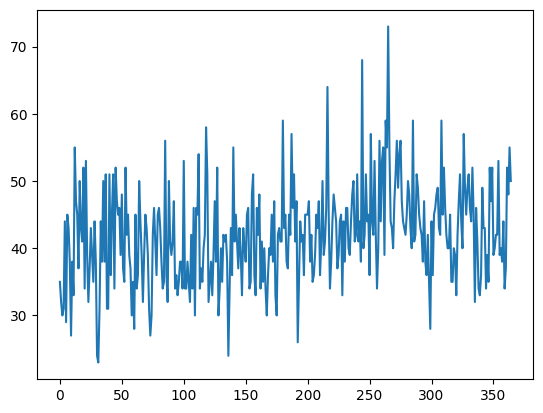

In [23]:
dataviz_df['births'].plot()

In [24]:
dataviz_df.index = dataviz_df['date']

<Axes: xlabel='date'>

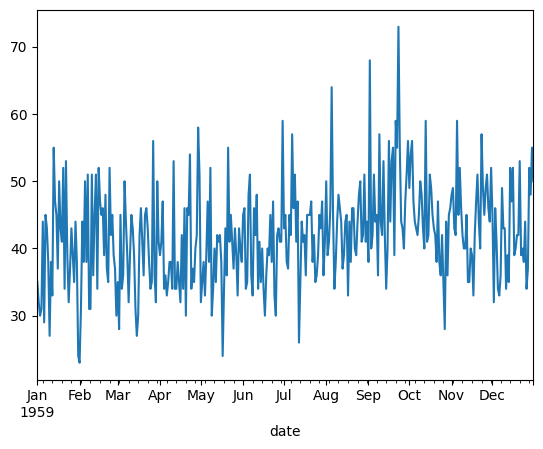

In [25]:
dataviz_df['births'].plot()

Zooming IN

In [26]:
dataviz_zom = dataviz_df[(dataviz_df['date'] > '1959-01-01') & (dataviz_df['date'] <='1959-01-10')].copy()

In [27]:
dataviz_zom

,date,births
date,,
1959-01-02,1959-01-02,32
1959-01-03,1959-01-03,30
1959-01-04,1959-01-04,31
1959-01-05,1959-01-05,44
1959-01-06,1959-01-06,29
1959-01-07,1959-01-07,45
1959-01-08,1959-01-08,43
1959-01-09,1959-01-09,38
1959-01-10,1959-01-10,27


<Axes: xlabel='date'>

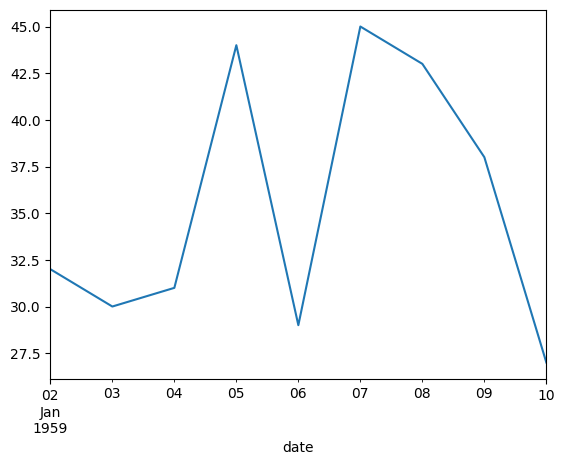

In [30]:
dataviz_zom['births'].plot()

Trend lines

In [31]:
import seaborn as sns

<Axes: ylabel='births'>

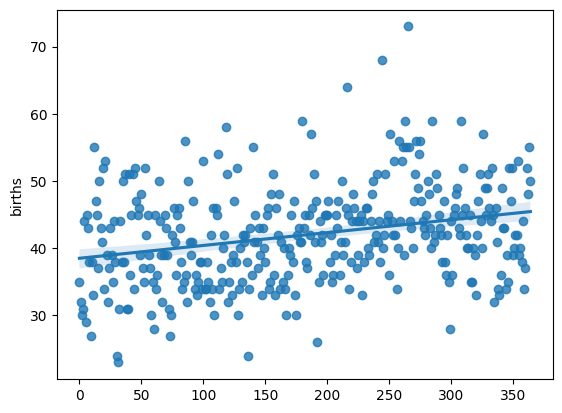

In [32]:
sns.regplot(x=df2.index.values,y=df2['births'])

<Axes: ylabel='births'>

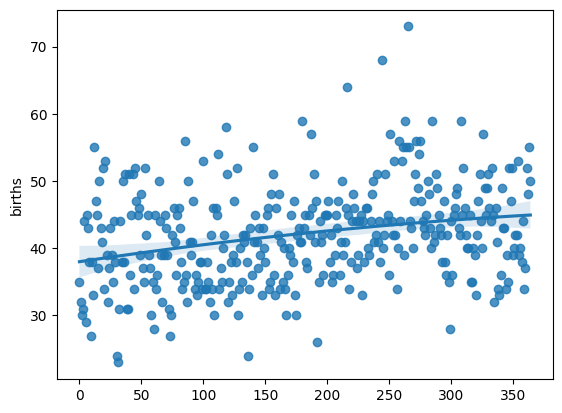

In [33]:
sns.regplot(x=df2.index.values,y=df2['births'],order=2)

In [34]:
miles_df=pd.read_csv("/content/us-airlines-monthly-aircraft-miles-flown.csv",header=0,parse_dates=[0])

In [35]:
miles_df.head()

,Month,MilesMM
0,1963-01-01,6827
1,1963-02-01,6178
2,1963-03-01,7084
3,1963-04-01,8162
4,1963-05-01,8462


<Axes: >

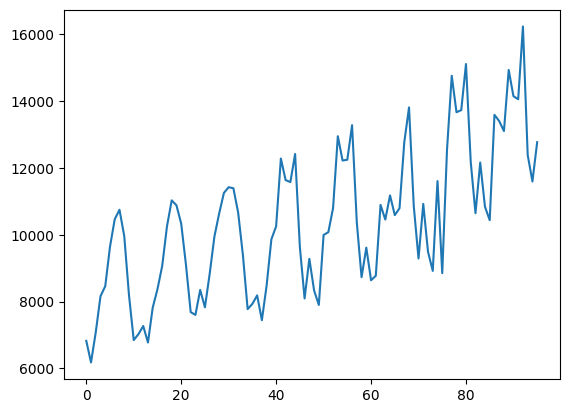

In [36]:
miles_df['MilesMM'].plot()

<Axes: ylabel='MilesMM'>

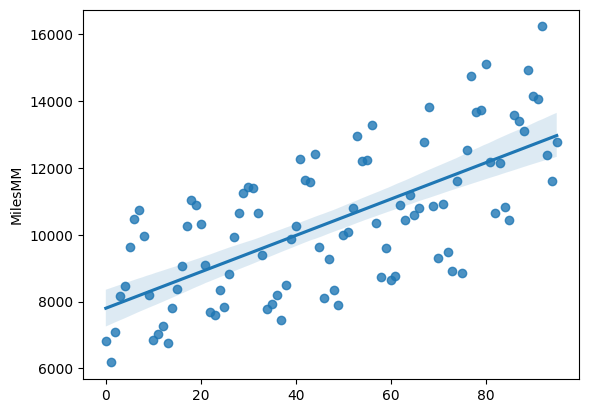

In [37]:
sns.regplot(x=miles_df.index.values, y=miles_df['MilesMM'])

Removing the Seasonality


In [38]:
miles_df['years']=miles_df['Month'].dt.year

In [39]:
miles_df.head()

,Month,MilesMM,years
0,1963-01-01,6827,1963
1,1963-02-01,6178,1963
2,1963-03-01,7084,1963
3,1963-04-01,8162,1963
4,1963-05-01,8462,1963


In [42]:
miles_df.groupby('years')['MilesMM'].mean()

,MilesMM
years,
1963,8300.250000
1964,8849.333333
1965,9619.250000
1966,9929.500000
1967,10542.916667
1968,10747.916667
1969,11972.000000
1970,13124.750000


<Axes: xlabel='years'>

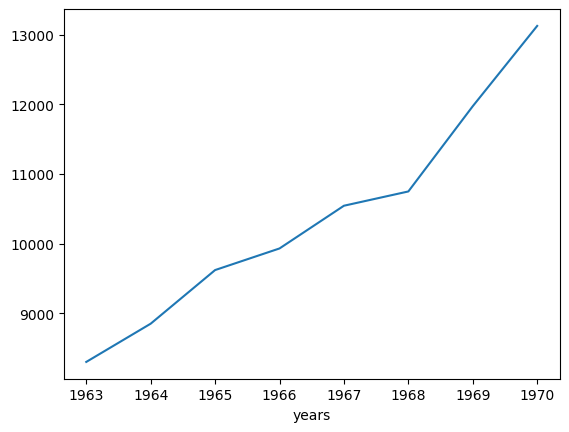

In [43]:
miles_df.groupby('years')['MilesMM'].mean().plot()

Creating the lag plOTS

In [44]:
miles_df['lag1']=miles_df['MilesMM'].shift(1)

In [45]:
miles_df.head()

,Month,MilesMM,years,lag1
0,1963-01-01,6827,1963,NaN
1,1963-02-01,6178,1963,6827.0
2,1963-03-01,7084,1963,6178.0
3,1963-04-01,8162,1963,7084.0
4,1963-05-01,8462,1963,8162.0


<Axes: xlabel='lag1', ylabel='MilesMM'>

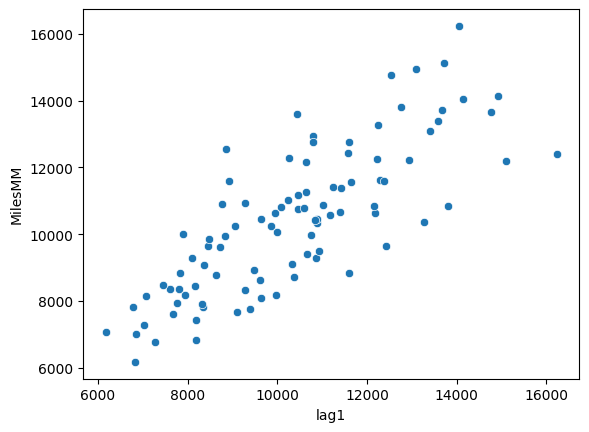

In [46]:
sns.scatterplot(x=miles_df['lag1'],y=miles_df['MilesMM'])

Auto correlation plots

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

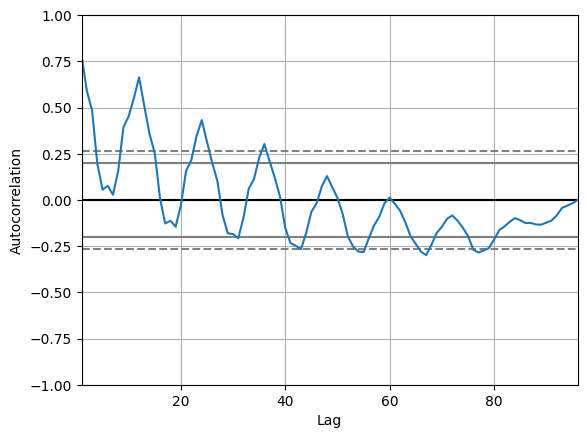

In [47]:
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(miles_df['MilesMM'])